In [1]:
# Chit 34: Credit-card fraud detection with an autoencoder
# Step 1: Load the credit-card transactions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

data = pd.read_csv("creditcard.csv")
X = data.drop(columns="Class").to_numpy(dtype="float32")
y = data["Class"].to_numpy(dtype="int32")
print("Rows and input columns:", X.shape)
print("Normal transactions:", int((y == 0).sum()))
print("Fraudulent transactions:", int((y == 1).sum()))

Rows and input columns: (284807, 30)
Normal transactions: 284315
Fraudulent transactions: 492


In [2]:
# Step 2: Split and scale the data
X_train_all, X_test_raw, y_train_all, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_normal = X_train_all[y_train_all == 0]
X_train, X_val = train_test_split(X_normal, test_size=0.1, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test_raw)

In [6]:
# Step 3: Build and train the autoencoder
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(16, activation="relu"),
    Dense(X_train.shape[1], activation="linear")
])
model.compile(optimizer="adam", loss="mse")
history = model.fit(X_train, X_train, 
                    epochs=10, 
                    batch_size=256, 
                    validation_data=(X_val, X_val), 
                    verbose=0
                   )


In [7]:
# Step 4: Flag possible fraud
val_reconstruction = model.predict(X_val, verbose=0)
val_errors = np.mean(np.square(X_val - val_reconstruction), axis=1)
threshold = np.percentile(val_errors, 95)

test_reconstruction = model.predict(X_test, verbose=0)
test_errors = np.mean(np.square(X_test - test_reconstruction), axis=1)
y_pred = (test_errors > threshold).astype(int)
print("Threshold:", round(float(threshold), 4))
print("Detected possible fraud:", int(y_pred.sum()))
print(classification_report(y_test, y_pred, target_names=["Normal", "Fraud"], zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Threshold: 1.0703
Detected possible fraud: 2905
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56864
       Fraud       0.03      0.86      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.90      0.52     56962
weighted avg       1.00      0.95      0.97     56962

Confusion matrix:
 [[54043  2821]
 [   14    84]]


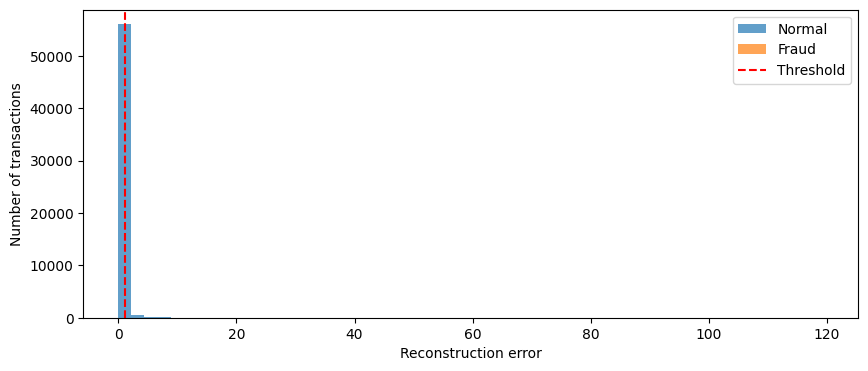

In [8]:
# Step 5: Plot reconstruction errors
plt.figure(figsize=(10, 4))
plt.hist(test_errors[y_test == 0], bins=50, alpha=0.7, label="Normal")
plt.hist(test_errors[y_test == 1], bins=50, alpha=0.7, label="Fraud")
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Reconstruction error")
plt.ylabel("Number of transactions")
plt.legend()
plt.show()